# FarmTech - resultados originais verificados

Análise executada nesta revisão a partir das evidências fornecidas. Não repete treinamento/inferência. Consulte o notebook principal para executar o pipeline completo. F1 macro e época CNN foram corrigidos; figuras permanecem evidências originais.

## 1. Ambiente, proveniência e partições
Classes YOLO: `0 = bottle`, `1 = coffee cup`. Todas as imagens selecionadas indicam licença CC BY 2.0 nos metadados individuais; autores, páginas de origem e licenças constam no CSV de atribuição.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
from collections import Counter
BASE=Path.cwd()/'openimages'
DATA=BASE/'dataset'
records=json.loads((BASE/'selected_images.json').read_text())
attrs=pd.read_csv(BASE/'attribution.csv')
print('Amostra:',len(records),'imagens | por classe:',dict(Counter(r['class'] for r in records)))
print('Licenças:',attrs['License'].value_counts().to_dict())
for split in ['train','val','test']:
    files=list((DATA/'images'/split).glob('*.jpg'))
    cls_counts=Counter(int(row.split()[0]) for p in files for row in (DATA/'labels'/split/f'{p.stem}.txt').read_text().splitlines())
    print(split,'| imagens:',len(files),'| instâncias por classe:',dict(cls_counts))
assert len(records)==80 and len({r['ImageID'] for r in records})==80


Amostra: 80 imagens | por classe: {'bottle': 40, 'coffee_cup': 40}
Licenças: {'https://creativecommons.org/licenses/by/2.0/': 80}
train | imagens: 64 | instâncias por classe: {1: 57, 0: 176}
val | imagens: 8 | instâncias por classe: {1: 7, 0: 17}
test | imagens: 8 | instâncias por classe: {1: 5, 0: 19}


## 2. Configuração e resultados do treino YOLO
YOLOv5n pré-treinado em COCO, 416×416, batch 8, semente 42, CPU, 2 workers. E30 e E60 usam os mesmos pesos iniciais e durações distintas. A duração também afeta a programação da taxa de aprendizagem. Checkpoints foram selecionados por validação.


In [2]:
import pandas as pd, re
runs = {}
for epochs in (30,60):
    run=BASE/f'runs/yolo_n_{epochs}ep'
    df=pd.read_csv(run/'results.csv'); df.columns=[c.strip() for c in df.columns]
    log=(BASE/f'logs/yolo{epochs}.log').read_text(errors='ignore')
    duration=re.search(rf'{epochs} epochs completed in ([0-9.]+) hours',log)
    native_val=re.findall(r'^\s*all\s+8\s+24\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)',log,re.M)
    best_row=df.loc[df['metrics/mAP_0.5:0.95'].idxmax()]
    runs[epochs]={'history':df,'best':best_row,'best_validation':list(map(float,native_val[-1])),
        'duration_hours':float(duration.group(1)) if duration else None}
summary=[]
for ep,r in runs.items():
    row=r['best']; pval,rval,m50,m95=r['best_validation']
    summary.append({'Épocas':ep,'P val':pval,'R val':rval,
        'mAP50 val':m50,'mAP50–95 val':m95,
        'Loss caixa treino':r['history'].iloc[-1]['train/box_loss'],
        'Loss caixa val':r['history'].iloc[-1]['val/box_loss'],
        'Treino (s)':r['duration_hours']*3600 if r['duration_hours'] else None})
pd.DataFrame(summary).round(3)


,Épocas,P val,R val,mAP50 val,mAP50–95 val,Loss caixa treino,Loss caixa val,Treino (s)
0,30,0.535,0.567,0.599,0.328,0.070,0.051,104.4
1,60,0.839,0.741,0.850,0.542,0.057,0.037,194.4


## 3. Comparação de detectores no teste
As métricas harmonizadas usam o mesmo conjunto de oito imagens, IoU 0,50, confiança 0,25 para precision/recall/F1 macro e AP50 interpolada em 101 pontos. O baseline COCO mapeia a categoria `cup` para `coffee cup` de forma aproximada.

In [3]:
det = json.loads((BASE/'detector_comparison.json').read_text())
rows=[]
for r in det:
    rows.append({'Modelo':r['model'],'P macro @0,25':r['macro_precision_conf025'],
        'R macro @0,25':r['macro_recall_conf025'],'F1 macro':r['macro_F1_conf025'],
        'mAP50 harmonizado':r['mAP50_101point'],'Latência ms':r['latency_ms_mean'],
        'DP latência ms':r['latency_ms_sd']})
pd.DataFrame(rows).round(3)


,Modelo,"P macro @0,25","R macro @0,25",F1 macro,mAP50 harmonizado,Latência ms,DP latência ms
0,COCO pretrained zero-shot,0.750,0.532,0.564,0.676,22.656,2.063
1,fine-tuned 30 ep,0.375,0.605,0.423,0.551,23.505,3.726
2,fine-tuned 60 ep,0.712,0.605,0.551,0.657,20.118,1.703


In [4]:
# Saída nativa do val.py nos splits de teste para os checkpoints ajustados.
import re
native=[]
for ep in (30,60):
    log=(BASE/f'logs/test{ep}.log').read_text(errors='ignore')
    rows=re.findall(r'^\s*all\s+8\s+24\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)',log,re.M)
    p,r,m50,m95=map(float,rows[-1])
    native.append({'Modelo':f'E{ep}','Precision teste':p,'Recall teste':r,'mAP50 teste':m50,'mAP50–95 teste':m95})
pd.DataFrame(native).round(3)


,Modelo,Precision teste,Recall teste,mAP50 teste,mAP50–95 teste
0,E30,0.833,0.400,0.480,0.285
1,E60,0.694,0.605,0.614,0.411


## 4. CNN do zero e matriz de confusão
CNN com quatro blocos convolucionais 16/32/64/128, ReLU, max-pooling, global average pooling e dropout 0,4. Adam (lr 0,001; weight decay 0,0001), até 50 épocas, parada por validação. Melhor checkpoint: época 37; encerramento efetivo: época 47.

In [5]:
cnn = json.loads((BASE/'cnn/metrics.json').read_text())
lat = json.loads((BASE/'cnn/latency_e2e.json').read_text())
print('Acurácia teste:',cnn['test_accuracy'],'| P/R/F1 macro:',cnn['precision_macro'],cnn['recall_macro'],cnn['f1_macro'])
print('Cross-entropy teste:',round(cnn['test_loss'],3),'| época selecionada por acurácia/loss:',cnn['best_epoch'],'| épocas executadas:',cnn['epochs_run'])
print('Matriz (linhas=real, colunas=prevista; ordem bottle, coffee cup):')
print(np.array(cnn['confusion_matrix']))
print('Tempo de treino (s):',round(cnn['train_seconds'],2),'| Latência e2e (ms/imagem):',round(lat['mean_ms_image'],2),'±',round(lat['sd_ms'],2))


Acurácia teste: 0.75 | P/R/F1 macro: 0.75 0.75 0.75
Cross-entropy teste: 0.611 | época selecionada por acurácia/loss: 37 | épocas executadas: 47
Matriz (linhas=real, colunas=prevista; ordem bottle, coffee cup):
[[3 1]
 [1 3]]
Tempo de treino (s): 26.66 | Latência e2e (ms/imagem): 6.42 ± 0.67


## 5. Arquitetura CNN
A fonte abaixo apresenta a arquitetura treinada. Esta célula inspeciona o código; não executa um novo forward do modelo.


In [6]:
# Inspect the supplied architecture without claiming a new torch forward pass.
from pathlib import Path
source=Path('train_cnn.py').read_text()
start=source.index('class CNN('); end=source.index('model=CNN()')
print(source[start:end])


class CNN(nn.Module):
 def __init__(self):
  super().__init__(); self.net=nn.Sequential(nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.4),nn.Linear(128,2))
 def forward(self,x): return self.net(x)



## 6. Curvas e exemplos do teste

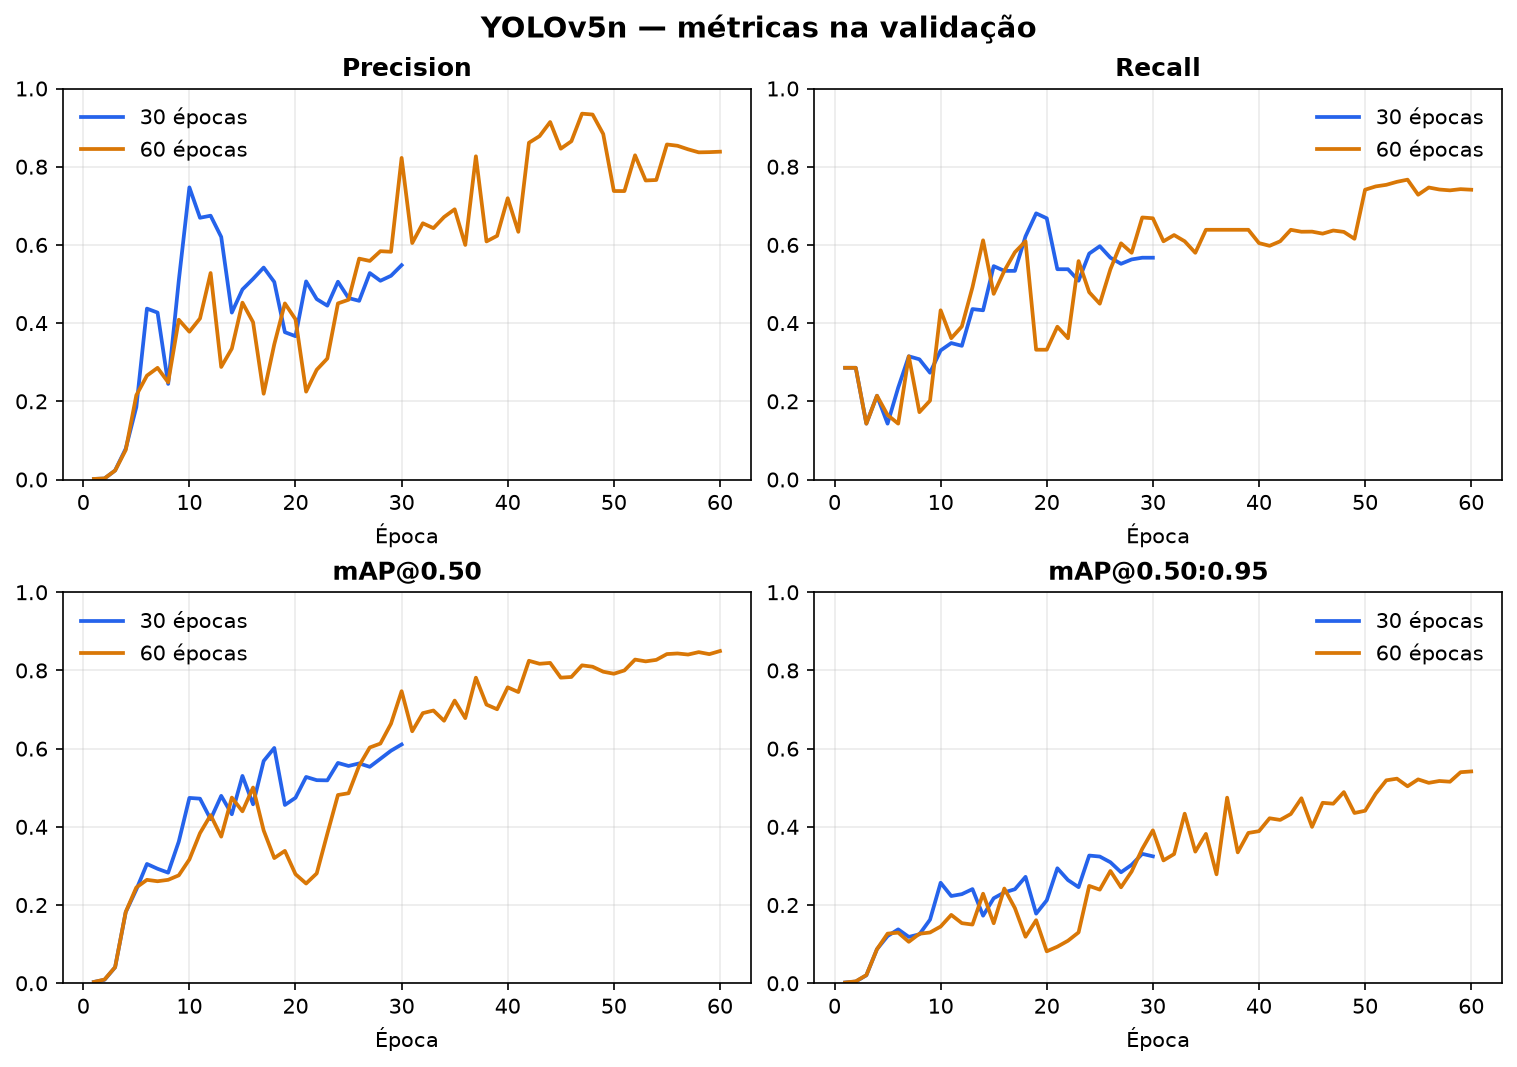

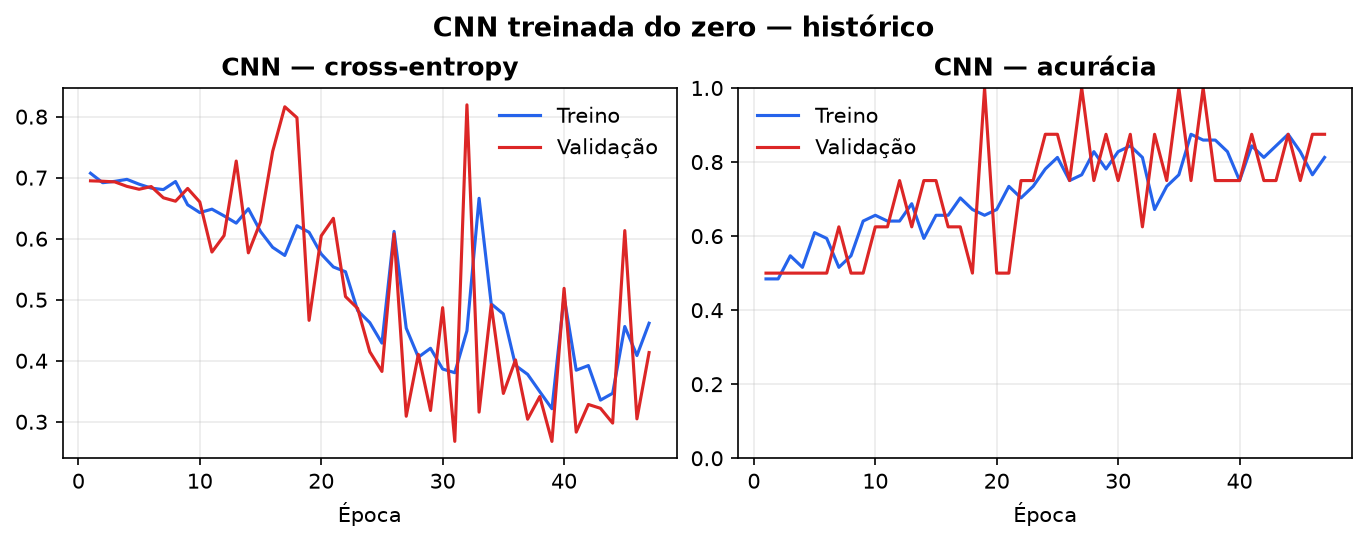

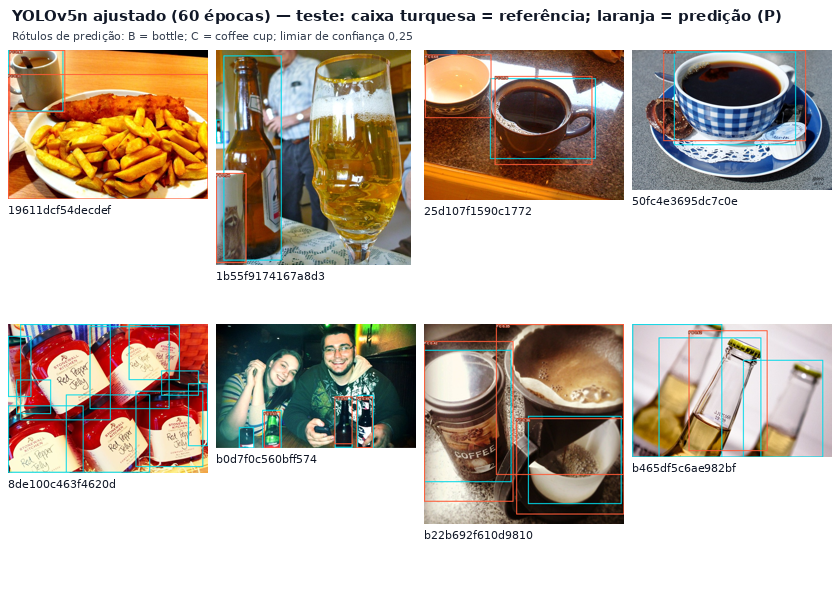

In [7]:
from IPython.display import display, Image as DisplayImage
for fn in ['curvas_yolo_validacao.png','curvas_cnn.png','predicoes_teste_yolo60.png']:
    print(fn)
    display(DisplayImage(filename=str(BASE/'figures'/fn)))


## Conclusão corrigida

E60 melhora E30 em validação e mAP de teste. No teste harmonizado, COCO tem mAP50 0,676 e F1 macro 0,564; E60 tem mAP50 0,657 e F1 macro 0,551, com recall macro maior (0,605 contra 0,532). Não se sustenta superioridade de E60 em F1 macro sobre COCO. A CNN acerta 6/8 imagens e o checkpoint foi selecionado na época 37 pelo desempate por loss. Oito imagens de teste e as tarefas distintas limitam a interpretação. Anotações públicas ainda não comprovam Make Sense AI.
